# Rostami et al.-Inspired Breast Cancer Autoencoder Representation

This notebook uses a breast-cancer-specific autoencoder representation inspired by:

**Rostami et al. (2025), _An autoencoder learning method for predicting breast cancer subtypes_, PLOS ONE.**  
PMCID: `PMC12286384`; DOI: `10.1371/journal.pone.0327773`.

The article trains simple subtype-specific autoencoders on breast cancer gene-expression data and uses the input-to-bottleneck weights to identify subtype-associated marker genes. Those marker genes are then used to classify breast cancer subtypes.

Here, we adapt the same idea to the current oligo/poly project:

1. use METABRIC breast cancer gene-expression data as the external breast-cancer training cohort;
2. train one simple autoencoder per major PAM50-like breast cancer subtype;
3. derive gene scores from the encoder weights;
4. select subtype-associated genes from the autoencoders;
5. project the institutional oligo/poly TPM cohort into autoencoder-derived representation spaces;
6. evaluate those representations using the same nested cross-validation and macro-F1 criterion used in the other transcriptomic representation-learning notebooks.

This is **not** a variational autoencoder. It is an article-inspired deterministic autoencoder and marker-selection representation.

## Analysis scope

This deterministic subtype-specific autoencoder experiment uses the full cBioPortal METABRIC source and evaluates two externally derived representations: marker-gene expression and subtype reconstruction errors. It adapts the original study to institutional oligo/poly classification rather than reproducing its subtype-prediction task.


In [1]:
# Display precision only; analytical values and saved artifacts stay unchanged.
from pathlib import Path as _DisplayPath
import sys as _display_sys
_display_root = _DisplayPath.cwd()
while not (_display_root / "scripts").is_dir() and _display_root != _display_root.parent:
    _display_root = _display_root.parent
if str(_display_root) not in _display_sys.path:
    _display_sys.path.insert(0, str(_display_root))
from scripts.OligoPolyThesis.utils_ml_oligopoly import thesis_display, thesis_print

import json
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import LabelEncoder
from sklearn.utils.class_weight import compute_class_weight
import warnings
from IPython.display import display, Markdown
ROOT = Path.cwd()
while not (ROOT / "scripts").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
if str(ROOT) not in sys.path: sys.path.insert(0, str(ROOT))
from scripts.OligoPolyThesis.utils_ml_oligopoly import (
    set_global_seed, split_transcriptomics_features_target_metadata,
    prepare_rostami_canonical, build_attention_classifiers, train_rostami_canonical,
    summarise_rostami_markers, rostami_reconstruction_scores, publish_rostami_bundle, load_rostami_bundle,
    metabric_source_fingerprint,
    validate_tpm_oof, rank_tpm_inner_scores, tpm_pooled_oof_metrics,
    evaluate_metabric_latent_representation, summarise_representation_results,
    extract_fitted_tpm_feature_rankings,
    plot_roc_curves, plot_precision_recall_curves, plot_confusion_matrix, plot_calibration_curve,
    plot_metric_boxplots, plot_train_test_gap_boxplots, plot_per_fold_lines,
    compute_representation_silhouette, plot_umap_representation,
    run_nested_flaml_metabric_latent, fit_metabric_latent_flaml,
)
RANDOM_STATE = 42
set_global_seed(RANDOM_STATE)
from scripts.OligoPolyThesis.utils_ml_oligopoly import display_interpretation
from scripts.OligoPolyThesis.utils_ml_oligopoly import select_mean_inner_combination


## Source data

Expression uses the full cBioPortal METABRIC matrix. Historical Pam50Subtype labels are joined by exact sample ID, retaining Basal, Her2, LumA and LumB. Normal and unknown labels are excluded; CLAUDIN_SUBTYPE is not substituted.


In [2]:
project_root = Path('/mnt/data3/MCPP-Breast')
external_root = project_root / 'Machine-Learning-Models-poly_vs_oligo/External-Data'
source_dir = external_root / 'cBioPortal/brca_metabric'
metabric_expression_path = source_dir / 'data_mrna_illumina_microarray.txt'
metadata_path = source_dir / 'meta_mrna_illumina_microarray.txt'
study_path = source_dir / 'meta_study.txt'
label_path = external_root / 'IntegrativeVAEs/IntegrativeVAEs-master/data/MBdata_33CLINwMiss_1KfGE_1KfCNA.csv'
institutional_expression_path = project_root / 'Transcriptomic-Data/Preprocessed/transcriptomics_oligo_poly_log2_tpm_preprocessed.csv'
gene_mapping_path = institutional_expression_path.with_name('transcriptomics_feature_name_mapping.csv')
source_paths = [metabric_expression_path, metadata_path, study_path, label_path, institutional_expression_path, gene_mapping_path]
output_dir = project_root / 'Machine-Learning-Models-poly_vs_oligo/Transcriptomics-BC-Specific-Representations/Rostami-Autoencoder/canonical-16950'
preparation_manifest = output_dir / 'rostami_preparation.json'
mobrcanet_repo_dir = external_root / 'moBRCA-net'


## Model specification

The architecture is 1,000 inputs → 500 ReLU units → 1,000 linear reconstruction outputs. Linear reconstruction is required because StandardScaler-transformed targets can be negative. MSE, Adam 0.001, batch 32, maximum 300 epochs and validation-loss early stopping with patience 30 and restored best weights are retained.


In [3]:
N_TOP_VARIABLE_GENES = 1000
ARTICLE_BOTTLENECK_DIM = 500
TOP_GENES_PER_SUBTYPE = 300
SEEDS = [42, 101, 202]
N_RUNS_PER_SUBTYPE = 3
VALIDATION_FRACTION = 0.2
BATCH_SIZE = 32
EPOCHS = 300
PATIENCE = 30
LEARNING_RATE = .001
RUN_PREPARE_SOURCE = True
RUN_ROSTAMI_ENCODERS = False
RUN_NESTED_CV = True
RUN_FLAML = False
RUN_FULL_COHORT_FLAML = False
RUN_INTEGRATED_GRADIENTS = False
RUN_EXPLORATORY = False
FLAML_TIME_BUDGET_SECONDS = 120
MARKER_REPRESENTATION_NAME = 'metabric_cbioportal_rostami_marker_expression'
RECONSTRUCTION_REPRESENTATION_NAME = 'metabric_cbioportal_rostami_reconstruction_errors'
subtypes_to_keep = ['Basal', 'Her2', 'LumA', 'LumB']
prepared = None
bundle = None
marker_latent_scores_df = None
reconstruction_scores_df = None
fixed_representations = {}
rostami_registry = {}
all_results, all_predictions = {}, {}
selected_combination = None


## Load METABRIC Expression and Subtype Labels

The complete cBioPortal expression matrix is aligned by sample ID to the available METABRIC PAM50 labels. Basal, Her2, LumA and LumB samples are retained; Normal and unknown labels are excluded from subtype-specific training.


In [4]:
# Canonical expression and exact subtype-label alignment are validated together in cell 15.


## Load Institutional Oligo/Poly TPM Data

We load the institutional transcriptomic matrix and separate transcriptomic features, oligo/poly target labels, and metadata.

In [5]:
## Load Institutional Oligo/Poly TPM Data ##

institutional_transcriptomics_df = pd.read_csv(
    institutional_expression_path
)

split_result = split_transcriptomics_features_target_metadata(
    transcriptomics_df=institutional_transcriptomics_df,
    target_col="Polymetastatic",
    feature_prefix="transcriptomics__",
)

institutional_expression_df = split_result[0]
y = split_result[1]
metadata_df = split_result[2]

thesis_print("Institutional expression matrix shape:")
thesis_print(institutional_expression_df.shape)

thesis_print("\nTarget distribution:")
thesis_print(y.value_counts().sort_index())

thesis_display(institutional_expression_df.head())
thesis_display(metadata_df.head())

Institutional expression matrix shape:
(139, 18260)

Target distribution:
Polymetastatic
0    54
1    85
Name: count, dtype: int64


,transcriptomics__ENSG00000000003,transcriptomics__ENSG00000000005,transcriptomics__ENSG00000000419,transcriptomics__ENSG00000000457,transcriptomics__ENSG00000000460,transcriptomics__ENSG00000000938,transcriptomics__ENSG00000000971,transcriptomics__ENSG00000001036,transcriptomics__ENSG00000001084,transcriptomics__ENSG00000001167,...,transcriptomics__ENSG00000289721,transcriptomics__ENSG00000289746,transcriptomics__ENSG00000289762,transcriptomics__ENSG00000290292,transcriptomics__ENSG00000291237,transcriptomics__ENSG00000291307,transcriptomics__ENSG00000291309,transcriptomics__ENSG00000291316,transcriptomics__ENSG00000291317,transcriptomics__ENSG00000293543
0,3.575,0.000,7.108,5.442,5.503,0.983,5.494,6.254,5.513,5.626,...,0.000,0.000,0.000,3.874,9.325,0.0,6.060,5.032,4.841,0.0
1,4.447,0.000,6.674,3.731,4.848,3.864,5.304,4.990,6.267,4.868,...,0.977,2.580,4.518,4.208,6.840,0.0,5.751,1.311,4.119,0.0
2,4.698,0.000,5.981,4.556,5.729,2.916,5.427,5.085,5.098,6.475,...,2.668,1.598,0.000,5.191,7.456,0.0,5.609,0.000,5.453,0.0
3,4.242,0.000,7.116,3.620,4.495,3.741,6.813,5.631,6.462,3.759,...,0.000,3.426,0.000,4.180,8.730,0.0,5.954,0.000,3.619,0.0
4,3.436,3.174,6.883,4.456,5.580,4.363,7.264,5.643,5.487,5.286,...,3.117,4.866,0.000,4.905,7.681,0.0,5.292,3.756,3.962,0.0


,sample_id_original,sample_id_normalised,transcriptomics_source,metastatic_group,Polymetastatic
0,101B.WTS_S57,101B,rnaseq_tpm_norm.txt,oligometastatic,0
1,108B.WTS_S64,108B,rnaseq_tpm_norm.txt,oligometastatic,0
2,10B.WTS_S24,10B,rnaseq_tpm_norm.txt,oligometastatic,0
3,110B.WTS_S66,110B,rnaseq_tpm_norm.txt,oligometastatic,0
4,115B.WTS_S2,115B,rnaseq_tpm_norm.txt,oligometastatic,0


## Map Institutional Ensembl IDs to Gene Symbols

METABRIC features are represented as gene symbols, while the institutional TPM matrix uses Ensembl IDs. We map the institutional features to gene symbols using the transcriptomics preprocessing mapping file.

In [6]:
gene_mapping_df = pd.read_csv(gene_mapping_path)
institutional_expression_df = institutional_expression_df.copy()
institutional_expression_df.index = metadata_df.sample_id_normalised.astype(str).to_numpy()


## Fixed external preparation

The common schema contains 16,950 genes. An 80:20 subtype-stratified split uses seed 42 and is shared across all initialisation seeds. Only external training samples fit imputation medians, the 1,000-gene variance ranking and StandardScaler. Frozen transformations apply to validation and institutional samples. Resolved duplicate METABRIC genes use per-sample mean expression; institutional genes are not aggregated.


In [7]:
if RUN_PREPARE_SOURCE or RUN_ROSTAMI_ENCODERS or RUN_INTEGRATED_GRADIENTS:
    prepared = prepare_rostami_canonical(metabric_expression_path, metadata_path, study_path,
        label_path, institutional_expression_df, gene_mapping_df, output_dir, source_paths, RANDOM_STATE)
    thesis_display(prepared['provenance']['pam50'])


{'canonical_samples': 1980,
 'validated_samples': 1974,
 'unmatched_samples': [],
 'duplicate_sample_ids': [],
 'conflicting_labels': [],
 'excluded_unknown_samples': ['MB-2778',
  'MB-4697',
  'MB-4224',
  'MB-6077',
  'MB-5339',
  'MB-7237'],
 'classes': ['Basal', 'Her2', 'LumA', 'LumB', 'Normal'],
 'class_counts': {'LumA': 718,
  'LumB': 488,
  'Basal': 329,
  'Her2': 240,
  'Normal': 199},
 'label_source': {'/mnt/data3/MCPP-Breast/Machine-Learning-Models-poly_vs_oligo/External-Data/IntegrativeVAEs/IntegrativeVAEs-master/data/MBdata_33CLINwMiss_1KfGE_1KfCNA.csv': {'sha256': '4d8c56dd8f01440782174071baa3b9d78a5630edfabe4f2663496f83bcc86b0c',
   'bytes': 22397867}},
 'rostami_class_counts': {'LumA': 718, 'LumB': 488, 'Basal': 329, 'Her2': 240},
 'rostami_eligible_samples': 1775}

## Frozen transformation and limitations

Microarray log2 intensity and RNA-seq log2-TPM remain different measurement domains. External-only scaling prevents institutional fitting but does not make the two platforms equivalent. The inherited institutional full-cohort X-only prevalence filter remains a limitation.


In [8]:
if prepared is not None:
    institutional_scaled_df = pd.DataFrame(prepared['scaler'].transform(prepared['institutional']).astype(np.float32),
        index=prepared['institutional'].index, columns=prepared['institutional'].columns)


## Subtype-specific deterministic autoencoders


## Fixed split, multiple initialisations

Four subtypes × seeds 42, 101 and 202 produce twelve models. Every model uses the same fixed external training/validation partition restricted to its subtype. The run stops if a subtype has too few independent samples. Marker scores aggregate all three seeds; reconstruction errors use the final seed-202 model per subtype. Reconstruction errors therefore reflect a single initialisation rather than an average across seeds.


In [9]:
if RUN_ROSTAMI_ENCODERS:
    rostami_run = train_rostami_canonical(prepared, output_dir)
    all_gene_scores_df = rostami_run['scores']


## Marker selection and seed stability

Each gene receives the L2 norm of its input-to-bottleneck weights. Mean scores across three seeds select the top 300 genes per subtype; their union defines marker expression. Score SD, top-300 recurrence and pairwise Spearman rank agreement describe stability. These unsigned external scores are not causal biomarkers or oligo/poly effects.


In [10]:
if RUN_ROSTAMI_ENCODERS:
    aggregated_gene_scores_df, selected_markers_df, marker_genes, rank_agreement_df = summarise_rostami_markers(all_gene_scores_df)
    aggregated_gene_scores_df.to_csv(rostami_run['artifacts'] / 'marker_stability.csv', index=False)
    selected_markers_df.to_csv(rostami_run['artifacts'] / 'selected_markers_by_subtype.csv', index=False)
    rank_agreement_df.to_csv(rostami_run['artifacts'] / 'seed_rank_agreement.csv', index=False)
    thesis_display(aggregated_gene_scores_df, rank_agreement_df)


## Plot Autoencoder Training Losses

We plot the training and validation losses for the subtype-specific autoencoders. These plots help check whether the simple article-inspired models converged.

In [11]:
if RUN_ROSTAMI_ENCODERS:
    for subtype in subtypes_to_keep:
        fig, ax = plt.subplots()
        for seed in SEEDS:
            h = rostami_run['histories'].query('subtype == @subtype and seed == @seed')
            ax.plot(h.epoch, h.loss, label=f'{seed} train')
            ax.plot(h.epoch, h.val_loss, linestyle='--', label=f'{seed} validation')
        ax.set(title=subtype, xlabel='Epoch', ylabel='MSE'); ax.legend(); plt.show()


## Two distinct institutional representations

Marker expression contains externally standardised expression for the selected gene union; its dimension is determined after external training. Reconstruction error contains four MSE features, one per subtype, computed with the seed-202 models. Neither representation is refitted using institutional data.


In [12]:
if RUN_ROSTAMI_ENCODERS:
    marker_latent_scores_df = institutional_scaled_df[marker_genes].rename(columns=lambda gene: f'{MARKER_REPRESENTATION_NAME}__{gene}').reset_index(drop=True)
    marker_latent_scores_df.insert(0, 'sample_id_normalised', institutional_scaled_df.index)


In [13]:
if RUN_ROSTAMI_ENCODERS:
    errors = rostami_reconstruction_scores(rostami_run['models'], institutional_scaled_df)
    reconstruction_scores_df = pd.DataFrame(errors, columns=[f'{RECONSTRUCTION_REPRESENTATION_NAME}__{s}' for s in subtypes_to_keep])
    reconstruction_scores_df.insert(0, 'sample_id_normalised', institutional_scaled_df.index)


## Artifact publication

All twelve models, preprocessing, feature mappings, seed histories, marker summaries and both representations are published together with source and preparation fingerprints. Incomplete or mismatched bundles are rejected. Historical reduced-source outputs are never used as fallbacks.


In [14]:
if RUN_ROSTAMI_ENCODERS:
    publish_rostami_bundle(rostami_run, prepared, marker_genes, marker_latent_scores_df, reconstruction_scores_df)
bundle = load_rostami_bundle(output_dir, source_paths)
if bundle is not None:
    marker_latent_scores_df = bundle['marker']
    reconstruction_scores_df = bundle['reconstruction']


# Downstream Evaluation of Article-Inspired Autoencoder Representations

We now evaluate the autoencoder-derived representations for oligo/poly classification using the same nested cross-validation framework as the other transcriptomic representation-learning analyses.

The representation-learning step used only METABRIC subtype labels. The institutional labels are used only here, during downstream supervised evaluation.

In [15]:
outer_cv = StratifiedKFold(5, shuffle=True, random_state=42)
inner_cv = StratifiedKFold(5, shuffle=True, random_state=42)
outer_splits = list(outer_cv.split(institutional_expression_df, y))
scoring = 'f1_macro'
configs_by_representation = {}
score_paths = {}


## Evaluate Marker-Gene Expression Representation

This representation uses expression values of genes selected by the subtype-specific autoencoder encoder weights. It is the closest adaptation of the article's marker-selection strategy.

In [16]:
for name, scores, filename in [
    (MARKER_REPRESENTATION_NAME, marker_latent_scores_df, 'marker_scores.csv'),
    (RECONSTRUCTION_REPRESENTATION_NAME, reconstruction_scores_df, 'reconstruction_scores.csv')]:
    if scores is None:
        if RUN_NESTED_CV: raise ValueError('Completed canonical representations required')
        continue
    if scores.sample_id_normalised.duplicated().any() or set(scores.sample_id_normalised)!=set(metadata_df.sample_id_normalised):
        raise ValueError('Each representation must contain exactly the institutional patients')
    merged = metadata_df[['sample_id_normalised','Polymetastatic']].merge(scores,on='sample_id_normalised',validate='one_to_one')
    if len(merged)!=139: raise ValueError('Expected 139 patients')
    X_repr = merged.filter(regex=f'^{name}__'); y_repr = merged.Polymetastatic.astype(int)
    fixed_representations[name] = (X_repr, y_repr)
    configs_by_representation[name] = build_attention_classifiers(RANDOM_STATE, X_repr.shape[1])
    score_paths[name] = bundle['root']/filename
    results, predictions = evaluate_metabric_latent_representation(X_repr, y_repr, name,
        merged[['sample_id_normalised','Polymetastatic']], metadata_df, y, outer_splits, inner_cv,
        output_dir, rostami_registry, score_paths[name], RUN_NESTED_CV, RANDOM_STATE,
        configs=configs_by_representation[name])
    all_results.update(results); all_predictions.update(predictions)



metabric_cbioportal_rostami_marker_expression_logreg_l1 | Outer fold 1


Best inner score:
0.375

Best params:
{'classifier__C': 1, 'classifier__class_weight': None, 'sampler': SMOTE(random_state=42), 'selector': 'passthrough'}

Test metrics:
{'roc_auc': 0.679, 'balanced_accuracy': 0.599, 'f1_macro': 0.571, 'precision': 0.727, 'recall': 0.471, 'specificity': 0.727, 'average_precision': 0.735, 'brier_score': 0.296}

metabric_cbioportal_rostami_marker_expression_logreg_l1 | Outer fold 2
Best inner score:
0.479

Best params:
{'classifier__C': 0.1, 'classifier__class_weight': 'balanced', 'sampler': 'passthrough', 'selector': 'passthrough'}

Test metrics:
{'roc_auc': 0.390, 'balanced_accuracy': 0.519, 'f1_macro': 0.509, 'precision': 0.619, 'recall': 0.765, 'specificity': 0.273, 'average_precision': 0.564, 'brier_score': 0.258}

metabric_cbioportal_rostami_marker_expression_logreg_l1 | Outer fold 3


Best inner score:
0.520

Best params:
{'classifier__C': 0.1, 'classifier__class_weight': None, 'sampler': SMOTE(random_state=42), 'selector': 'passthrough'}

Test metrics:
{'roc_auc': 0.428, 'balanced_accuracy': 0.492, 'f1_macro': 0.490, 'precision': 0.6, 'recall': 0.529, 'specificity': 0.455, 'average_precision': 0.560, 'brier_score': 0.268}

metabric_cbioportal_rostami_marker_expression_logreg_l1 | Outer fold 4
Best inner score:
0.547

Best params:
{'classifier__C': 0.1, 'classifier__class_weight': 'balanced', 'sampler': 'passthrough', 'selector': 'passthrough'}

Test metrics:
{'roc_auc': 0.481, 'balanced_accuracy': 0.508, 'f1_macro': 0.497, 'precision': 0.615, 'recall': 0.471, 'specificity': 0.545, 'average_precision': 0.594, 'brier_score': 0.252}

metabric_cbioportal_rostami_marker_expression_logreg_l1 | Outer fold 5


Best inner score:
0.574

Best params:
{'classifier__C': 0.1, 'classifier__class_weight': None, 'sampler': SMOTE(random_state=42), 'selector': 'passthrough'}

Test metrics:
{'roc_auc': 0.376, 'balanced_accuracy': 0.435, 'f1_macro': 0.432, 'precision': 0.571, 'recall': 0.471, 'specificity': 0.4, 'average_precision': 0.581, 'brier_score': 0.300}

metabric_cbioportal_rostami_marker_expression_random_forest | Outer fold 1


Best inner score:
0.438

Best params:
{'classifier__class_weight': 'balanced', 'classifier__max_depth': 2, 'classifier__max_features': 0.1, 'classifier__min_samples_leaf': 5, 'classifier__n_estimators': 100, 'sampler': 'passthrough', 'selector': 'passthrough'}

Test metrics:
{'roc_auc': 0.690, 'balanced_accuracy': 0.730, 'f1_macro': 0.733, 'precision': 0.778, 'recall': 0.824, 'specificity': 0.636, 'average_precision': 0.710, 'brier_score': 0.236}

metabric_cbioportal_rostami_marker_expression_random_forest | Outer fold 2


...

Best inner score:
0.485

Best params:
{'classifier__colsample_bytree': 0.05, 'classifier__learning_rate': 0.05, 'classifier__max_depth': 2, 'classifier__min_child_weight': 3, 'classifier__n_estimators': 50, 'classifier__reg_alpha': 0, 'classifier__reg_lambda': 5, 'classifier__subsample': 0.8, 'sampler': SMOTE(random_state=42), 'selector': 'passthrough'}

Test metrics:
{'roc_auc': 0.348, 'balanced_accuracy': 0.326, 'f1_macro': 0.326, 'precision': 0.471, 'recall': 0.471, 'specificity': 0.182, 'average_precision': 0.552, 'brier_score': 0.268}

metabric_cbioportal_rostami_reconstruction_errors_xgboost | Outer fold 2


Best inner score:
0.429

Best params:
{'classifier__colsample_bytree': 0.05, 'classifier__learning_rate': 0.01, 'classifier__max_depth': 2, 'classifier__min_child_weight': 5, 'classifier__n_estimators': 30, 'classifier__reg_alpha': 1, 'classifier__reg_lambda': 5, 'classifier__subsample': 0.8, 'sampler': SMOTE(random_state=42), 'selector': 'passthrough'}

Test metrics:
{'roc_auc': 0.586, 'balanced_accuracy': 0.551, 'f1_macro': 0.551, 'precision': 0.647, 'recall': 0.647, 'specificity': 0.455, 'average_precision': 0.743, 'brier_score': 0.249}

metabric_cbioportal_rostami_reconstruction_errors_xgboost | Outer fold 3


Best inner score:
0.576

Best params:
{'classifier__colsample_bytree': 0.05, 'classifier__learning_rate': 0.01, 'classifier__max_depth': 1, 'classifier__min_child_weight': 3, 'classifier__n_estimators': 30, 'classifier__reg_alpha': 1, 'classifier__reg_lambda': 1, 'classifier__subsample': 0.6, 'sampler': SMOTE(random_state=42), 'selector': 'passthrough'}

Test metrics:
{'roc_auc': 0.388, 'balanced_accuracy': 0.430, 'f1_macro': 0.429, 'precision': 0.556, 'recall': 0.588, 'specificity': 0.273, 'average_precision': 0.548, 'brier_score': 0.252}

metabric_cbioportal_rostami_reconstruction_errors_xgboost | Outer fold 4


Best inner score:
0.533

Best params:
{'classifier__colsample_bytree': 0.05, 'classifier__learning_rate': 0.01, 'classifier__max_depth': 1, 'classifier__min_child_weight': 5, 'classifier__n_estimators': 50, 'classifier__reg_alpha': 1, 'classifier__reg_lambda': 5, 'classifier__subsample': 0.6, 'sampler': SMOTE(random_state=42), 'selector': 'passthrough'}

Test metrics:
{'roc_auc': 0.414, 'balanced_accuracy': 0.524, 'f1_macro': 0.5, 'precision': 0.636, 'recall': 0.412, 'specificity': 0.636, 'average_precision': 0.640, 'brier_score': 0.251}

metabric_cbioportal_rostami_reconstruction_errors_xgboost | Outer fold 5


Best inner score:
0.589

Best params:
{'classifier__colsample_bytree': 0.05, 'classifier__learning_rate': 0.05, 'classifier__max_depth': 2, 'classifier__min_child_weight': 3, 'classifier__n_estimators': 50, 'classifier__reg_alpha': 1, 'classifier__reg_lambda': 5, 'classifier__subsample': 0.8, 'sampler': SMOTE(random_state=42), 'selector': 'passthrough'}

Test metrics:
{'roc_auc': 0.265, 'balanced_accuracy': 0.315, 'f1_macro': 0.310, 'precision': 0.5, 'recall': 0.529, 'specificity': 0.1, 'average_precision': 0.533, 'brier_score': 0.265}


## Evaluate Subtype Reconstruction-Error Representation

This representation uses one feature per subtype-specific autoencoder: the reconstruction error of each institutional sample under the corresponding subtype model.

The intuition is that a sample may be reconstructed better by subtype-specific autoencoders whose learned expression structure is closer to that sample.

In [17]:
# Both representations are evaluated in cell 33 using identical outer splits and classifier policy.


## Compare Article-Inspired Autoencoder Representations

We compare the two autoencoder-derived representations using the standard representation-selection quantity: mean inner-cross-validation macro-F1.

Outer-fold test metrics are interpreted as out-of-training performance estimates, not as model-selection criteria.

,representation,outer_fold,sampler,class_weight,scale_pos_weight
0,metabric_cbioportal_rostami_marker_expression_...,1,SMOTE(random_state=42),None,1
1,metabric_cbioportal_rostami_marker_expression_...,2,passthrough,balanced,1
2,metabric_cbioportal_rostami_marker_expression_...,3,SMOTE(random_state=42),None,1
3,metabric_cbioportal_rostami_marker_expression_...,4,passthrough,balanced,1
4,metabric_cbioportal_rostami_marker_expression_...,5,SMOTE(random_state=42),None,1
5,metabric_cbioportal_rostami_marker_expression_...,1,passthrough,balanced,1
6,metabric_cbioportal_rostami_marker_expression_...,2,SMOTE(random_state=42),None,1
7,metabric_cbioportal_rostami_marker_expression_...,3,SMOTE(random_state=42),None,1
8,metabric_cbioportal_rostami_marker_expression_...,4,SMOTE(random_state=42),None,1
9,metabric_cbioportal_rostami_marker_expression_...,5,SMOTE(random_state=42),None,1


,mean_inner_cv_score,std_inner_cv_score,mean_test_roc_auc,mean_test_balanced_accuracy,mean_train_roc_auc,train_test_gap,mean_rank,outer_fold_wins
representation,,,,,,,,
metabric_cbioportal_rostami_marker_expression_xgboost,0.548,0.037,0.428,0.423,0.912,0.485,2.2,3
metabric_cbioportal_rostami_reconstruction_errors_xgboost,0.522,0.066,0.400,0.429,0.714,0.314,3.2,0
metabric_cbioportal_rostami_marker_expression_random_forest,0.514,0.058,0.496,0.502,0.995,0.500,3.6,0
metabric_cbioportal_rostami_reconstruction_errors_random_forest,0.507,0.065,0.480,0.440,0.808,0.328,3.6,1
metabric_cbioportal_rostami_marker_expression_logreg_l1,0.499,0.078,0.471,0.511,0.851,0.380,3.8,0
metabric_cbioportal_rostami_reconstruction_errors_logreg_l1,0.484,0.054,0.476,0.474,0.558,0.082,4.6,1


,roc_auc,balanced_accuracy,f1_macro,precision,recall,specificity,average_precision,brier_score
representation,,,,,,,,
metabric_cbioportal_rostami_marker_expression_logreg_l1,0.501,0.511,0.508,0.622,0.541,0.481,0.628,0.275
metabric_cbioportal_rostami_marker_expression_random_forest,0.493,0.501,0.496,0.612,0.706,0.296,0.604,0.249
metabric_cbioportal_rostami_marker_expression_xgboost,0.426,0.424,0.422,0.556,0.588,0.259,0.581,0.255
metabric_cbioportal_rostami_reconstruction_errors_logreg_l1,0.476,0.474,0.464,0.585,0.447,0.500,0.623,0.251
metabric_cbioportal_rostami_reconstruction_errors_random_forest,0.462,0.442,0.441,0.568,0.588,0.296,0.621,0.258
metabric_cbioportal_rostami_reconstruction_errors_xgboost,0.380,0.431,0.432,0.556,0.529,0.333,0.548,0.257


train_roc_auc            \
                                                            mean       std   
representation                                                               
metabric_cbioportal_rostami_marker_expression_l...      0.851  0.097   
metabric_cbioportal_rostami_marker_expression_r...      0.995  0.008   
metabric_cbioportal_rostami_marker_expression_x...      0.912  0.071   
metabric_cbioportal_rostami_reconstruction_erro...      0.558  0.019   
metabric_cbioportal_rostami_reconstruction_erro...      0.808  0.038   
metabric_cbioportal_rostami_reconstruction_erro...      0.714  0.088   

                                                   train_balanced_accuracy  \
                                                                      mean   
representation                                                               
metabric_cbioportal_rostami_marker_expression_l...                0.780   
metabric_cbioportal_rostami_marker_expression_r...                0.968   
metabric_cbioportal_rostami_marker_expression_x...                0.842   
metabric_cbioportal_rostami_reconstruction_erro...                0.552   
metabric_cbioportal_rostami_reconstruction_erro...                0.717   
metabric_cbioportal_rostami_reconstruction_erro...                0.647   

                                                             train_f1_macro  \
                                                         std           mean   
representation                                                                
metabric_cbioportal_rostami_marker_expression_l...  0.126       0.772   
metabric_cbioportal_rostami_marker_expression_r...  0.022       0.971   
metabric_cbioportal_rostami_marker_expression_x...  0.089       0.845   
metabric_cbioportal_rostami_reconstruction_erro...  0.024       0.522   
metabric_cbioportal_rostami_reconstruction_erro...  0.041       0.712   
metabric_cbioportal_rostami_reconstruction_erro...  0.094       0.641   

                                                             train_precision  \
                                                         std            mean   
representation                                                                 
metabric_cbioportal_rostami_marker_expression_l...  0.131        0.849   
metabric_cbioportal_rostami_marker_expression_r...  0.018        0.967   
metabric_cbioportal_rostami_marker_expression_x...  0.091        0.868   
metabric_cbioportal_rostami_reconstruction_erro...  0.021        0.679   
metabric_cbioportal_rostami_reconstruction_erro...  0.043        0.792   
metabric_cbioportal_rostami_reconstruction_erro...  0.097        0.738   

                                                             train_recall  \
                                                         std         mean   
representation                                                              
metabric_cbioportal_rostami_marker_expression_l...  0.087     0.768   
metabric_cbioportal_rostami_marker_expression_r...  0.031     0.991   
metabric_cbioportal_rostami_marker_expression_x...  0.063     0.897   
metabric_cbioportal_rostami_reconstruction_erro...  0.035     0.424   
metabric_cbioportal_rostami_reconstruction_erro...  0.045     0.753   
metabric_cbioportal_rostami_reconstruction_erro...  0.074     0.656   

                                                              ... test_recall  \
                                                         std  ...        mean   
representation                                                ...               
metabric_cbioportal_rostami_marker_expression_l...  0.142  ...    0.541   
metabric_cbioportal_rostami_marker_expression_r...  0.020  ...    0.706   
metabric_cbioportal_rostami_marker_expression_x...  0.077  ...    0.588   
metabric_cbioportal_rostami_reconstruction_erro...  0.062  ...    0.447   
metabric_cbioportal_rostami_reconstruction_erro...  0.097  ...    0.588   
metabric_cbioportal_rostami_reconstruction_erro...  0.130  ...

,outer_fold,representation,best_inner_score,rank,is_winner
0,1,metabric_cbioportal_rostami_reconstruction_err...,0.538,1,True
1,1,metabric_cbioportal_rostami_reconstruction_err...,0.515,2,False
2,1,metabric_cbioportal_rostami_marker_expression_...,0.500,3,False
3,1,metabric_cbioportal_rostami_reconstruction_err...,0.485,4,False
4,1,metabric_cbioportal_rostami_marker_expression_...,0.438,5,False
5,1,metabric_cbioportal_rostami_marker_expression_...,0.375,6,False
6,2,metabric_cbioportal_rostami_marker_expression_...,0.524,1,True
7,2,metabric_cbioportal_rostami_marker_expression_...,0.487,2,False
8,2,metabric_cbioportal_rostami_marker_expression_...,0.479,3,False
9,2,metabric_cbioportal_rostami_reconstruction_err...,0.443,4,False


,outer_fold_wins
representation,
metabric_cbioportal_rostami_marker_expression_logreg_l1,0
metabric_cbioportal_rostami_marker_expression_random_forest,0
metabric_cbioportal_rostami_marker_expression_xgboost,3
metabric_cbioportal_rostami_reconstruction_errors_logreg_l1,1
metabric_cbioportal_rostami_reconstruction_errors_random_forest,1
metabric_cbioportal_rostami_reconstruction_errors_xgboost,0


Selected by mean inner-CV macro-F1: metabric_cbioportal_rostami_marker_expression_xgboost


/home/martapimentel/proj-mcpp-breast/scripts/OligoPolyThesis/utils_ml_oligopoly.py:5686: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


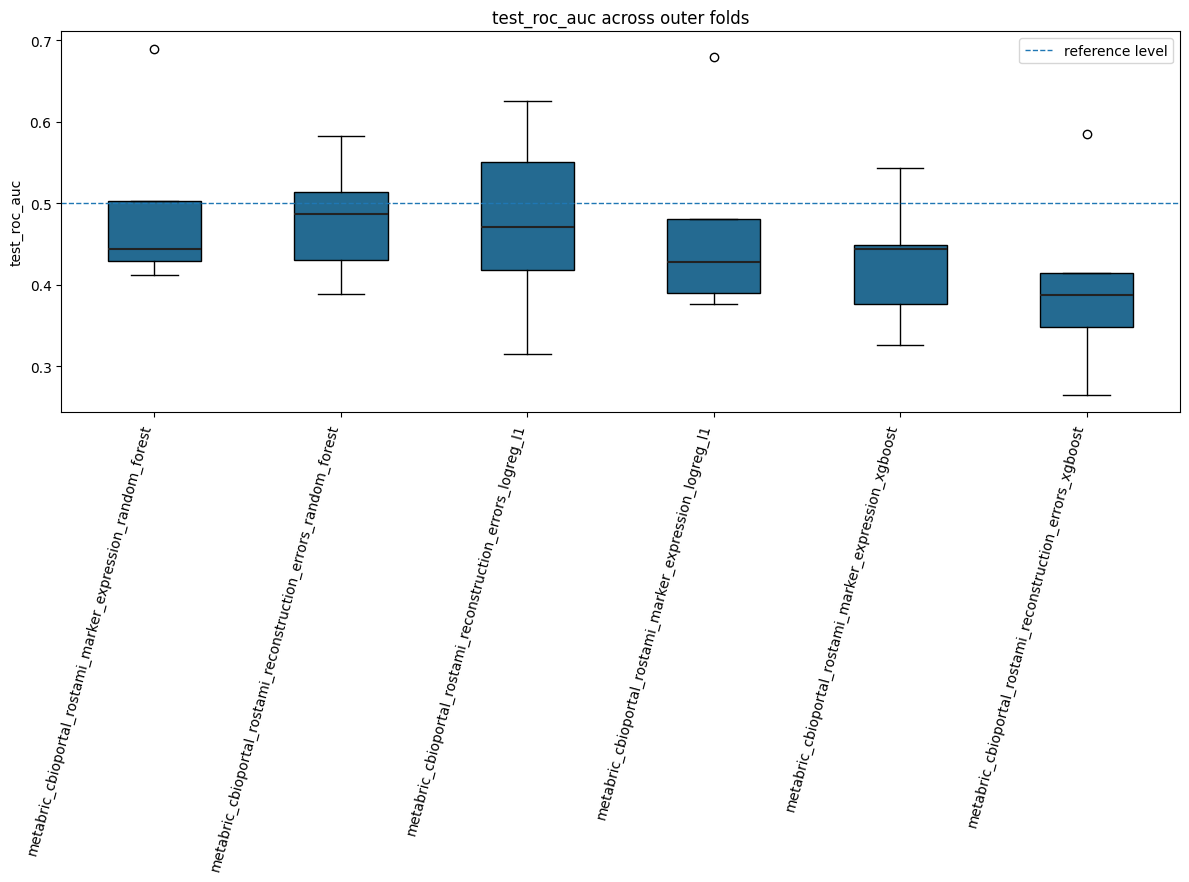

/home/martapimentel/proj-mcpp-breast/scripts/OligoPolyThesis/utils_ml_oligopoly.py:5732: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


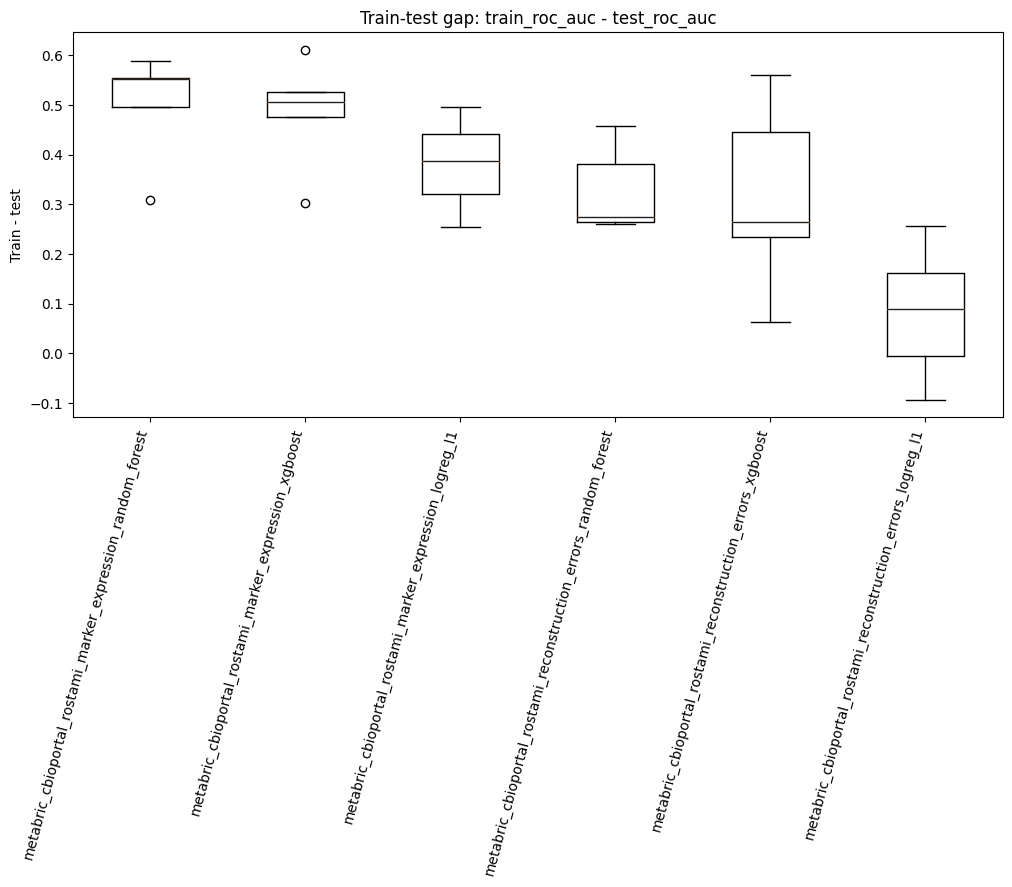

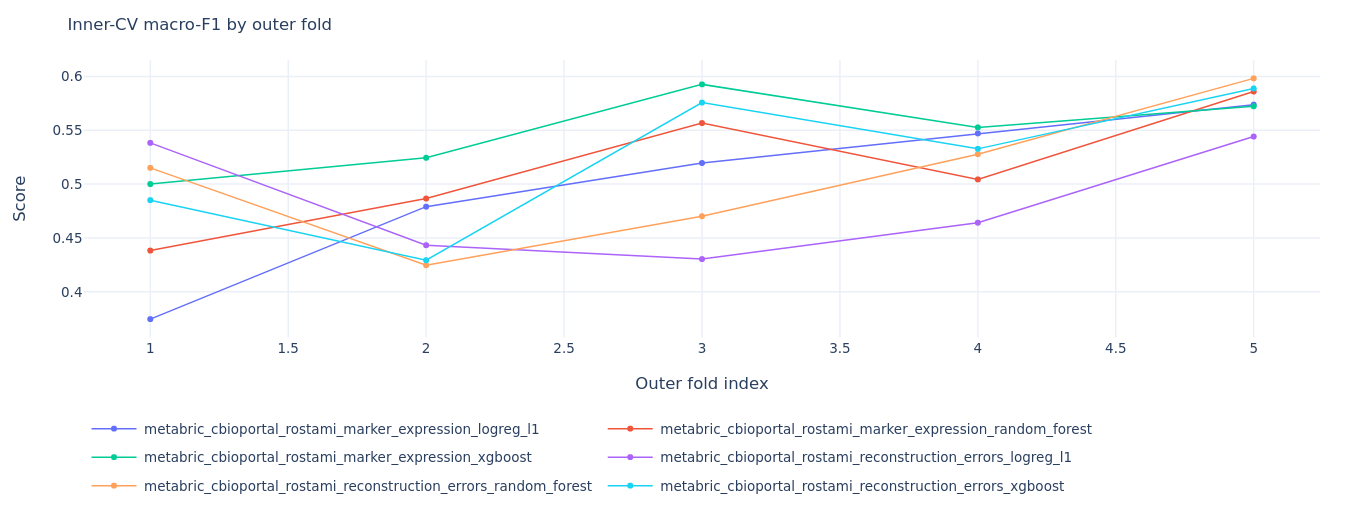

/tmp/ipykernel_34810/2556832751.py:44: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout(); plt.show()


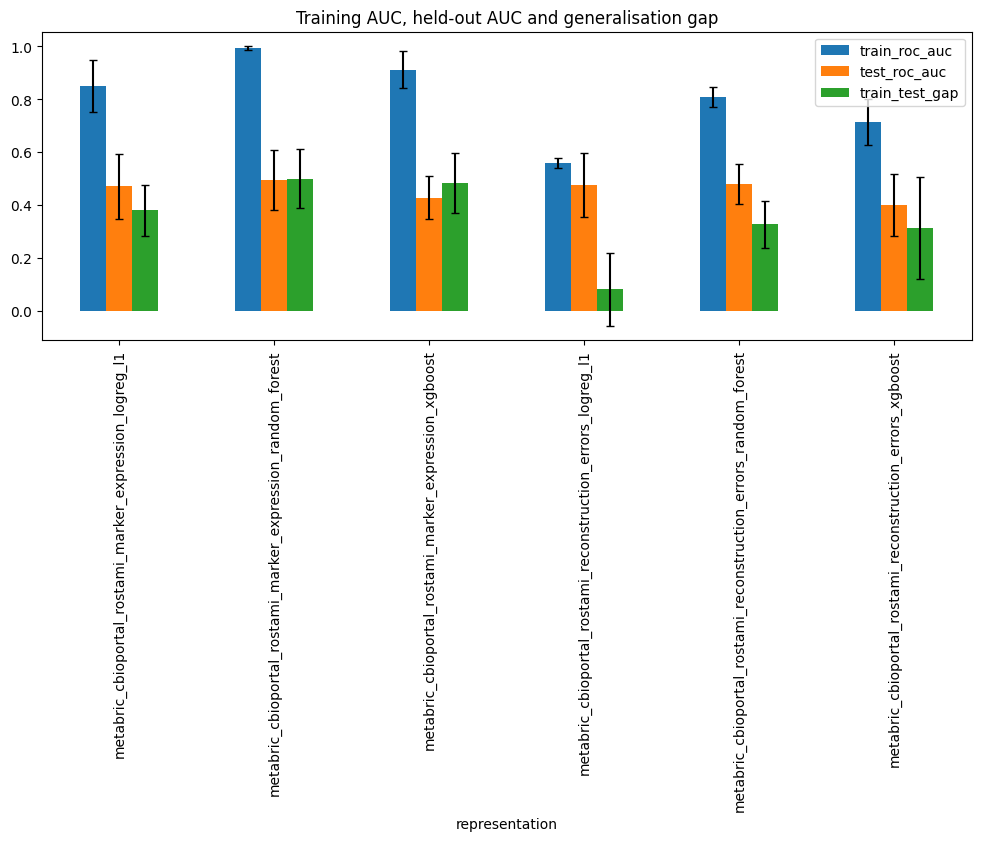

Apparent outer-training minus held-out outer-test performance; an overfitting diagnostic, not an inner-validation score.

In [18]:
selected_combination = None
if len(all_results) == 6 and set(all_results) == set(rostami_registry):
    for name in all_results:
        for frame in [all_results[name], all_predictions[name]]:
            frame['classifier_family'] = rostami_registry[name]['family']
            frame['source_representation'] = rostami_registry[name]['representation']
    all_metabric_representation_results_df = pd.concat(all_results.values(), ignore_index=True)
    inner_rankings_df, inner_wins_df = rank_tpm_inner_scores(all_metabric_representation_results_df, list(rostami_registry))
    validated_oof = {name: validate_tpm_oof(all_predictions[name], name, metadata_df, y, outer_splits) for name in all_results}
    for name, frame in validated_oof.items():
        extra = all_results[name][['outer_fold', 'best_inner_score', 'best_params']]
        validated_oof[name] = frame.drop(columns=['best_inner_score', 'best_params'], errors='ignore').merge(extra, on='outer_fold', validate='many_to_one')
    pooled_oof_df = pd.DataFrame([{"representation": name, **tpm_pooled_oof_metrics(frame)} for name, frame in validated_oof.items()]).set_index("representation")
    summary_df = summarise_representation_results(all_metabric_representation_results_df)
    summary_df = summary_df.join(inner_rankings_df.groupby('representation')['rank'].mean().rename('mean_rank')).join(inner_wins_df)
    selected_combination = select_mean_inner_combination(summary_df)
    all_metabric_representation_results_df['train_test_auc_gap'] = all_metabric_representation_results_df.train_roc_auc - all_metabric_representation_results_df.test_roc_auc
    fold_metric_cols = [c for c in all_metabric_representation_results_df if c.startswith(("train_", "test_"))]
    fold_summary_df = all_metabric_representation_results_df.groupby("representation")[fold_metric_cols].agg(["mean", "std"])
    for stem, frame, use_index in [
        ("all_nested_cv_results", all_metabric_representation_results_df, False),
        ("all_oof_predictions", pd.concat(validated_oof.values(), ignore_index=True), False),
        ("model_selection_summary", summary_df, True), ("fold_metrics_mean_sd", fold_summary_df, True),
        ("pooled_oof_metrics", pooled_oof_df, True), ("inner_fold_rankings", inner_rankings_df, False),
        ("inner_fold_win_counts", inner_wins_df, True)]:
        frame.to_csv(output_dir / f"rostami_{stem}_reviewed.csv", index=use_index)
    sampler_rows = []
    for row in all_metabric_representation_results_df.itertuples():
        params = json.loads(row.best_params)
        sampler_rows.append(dict(representation=row.representation, outer_fold=row.outer_fold, sampler=params.get('sampler', 'passthrough'), class_weight=params.get('classifier__class_weight'), scale_pos_weight=params.get('classifier__scale_pos_weight', 1)))
    sampler_summary = pd.DataFrame(sampler_rows)
    sampler_summary.to_csv(output_dir / 'rostami_sampler_weighting_reviewed.csv', index=False)
    thesis_display(sampler_summary)
    thesis_display(summary_df, pooled_oof_df, fold_summary_df, inner_rankings_df, inner_wins_df)
    thesis_print("Selected by mean inner-CV macro-F1:", selected_combination)
    plot_metric_boxplots(all_metabric_representation_results_df, metric="test_roc_auc", top_n=6, chance_level=0.5)
    plot_train_test_gap_boxplots(all_metabric_representation_results_df, train_col="train_roc_auc", test_col="test_roc_auc", top_n=6)
    plot_per_fold_lines(all_metabric_representation_results_df.pivot(index="outer_fold", columns="representation", values="best_inner_score"), title="Inner-CV macro-F1 by outer fold", interactive=False)
    train_test_means = all_metabric_representation_results_df.groupby("representation")[["train_roc_auc", "test_roc_auc"]].mean()
    train_test_means["train_test_gap"] = train_test_means.train_roc_auc - train_test_means.test_roc_auc
    train_test_means.to_csv(output_dir / "rostami_train_test_comparison_reviewed.csv")
    train_test_sd = all_metabric_representation_results_df.assign(train_test_gap=all_metabric_representation_results_df.train_test_auc_gap).groupby('representation')[['train_roc_auc', 'test_roc_auc', 'train_test_gap']].std()
    train_test_means.plot.bar(yerr=train_test_sd, capsize=3, figsize=(12, 12), title="Training AUC, held-out AUC and generalisation gap")
    plt.tight_layout(); plt.show()
else:
    thesis_print("Complete canonical results for all six combinations are required for global selection.")
display(Markdown('Apparent outer-training minus held-out outer-test performance; an overfitting diagnostic, not an inner-validation score.'))


## Training, held-out performance and selection

Marker expression + XGBoost (`metabric_cbioportal_rostami_marker_expression_xgboost`) was selected because it had the highest mean inner-CV macro-F1, 0.548387 ± 0.036914. It won 3/5 outer-fold inner-score rankings, but the predefined criterion was the mean inner score, not the number of wins. Other combinations' higher outer-test metrics do not justify changing this selection retrospectively.

Mean training ROC-AUC was 0.912369, compared with mean outer-test ROC-AUC 0.427701. The mean train–test AUC gap of 0.484669 is consistent with substantial overfitting and poor generalisation. Fold-specific mean ± SD and pooled OOF metrics describe different summaries of the held-out predictions; neither is used to select the global combination. Uncertainty remains substantial at N=139.


--- Plotting ROC Curve ---


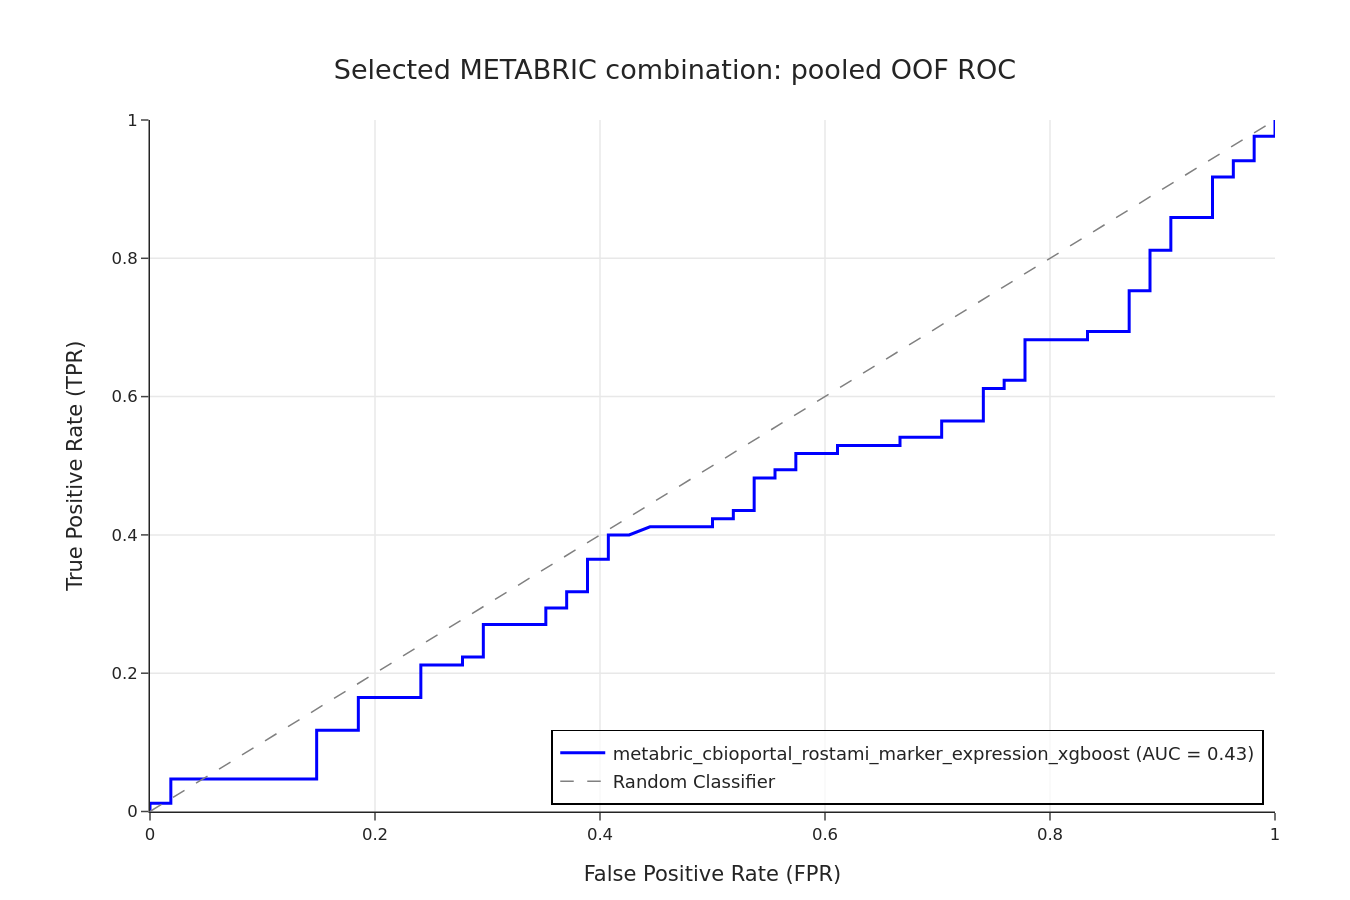

--- Plotting Precision–Recall Curve ---


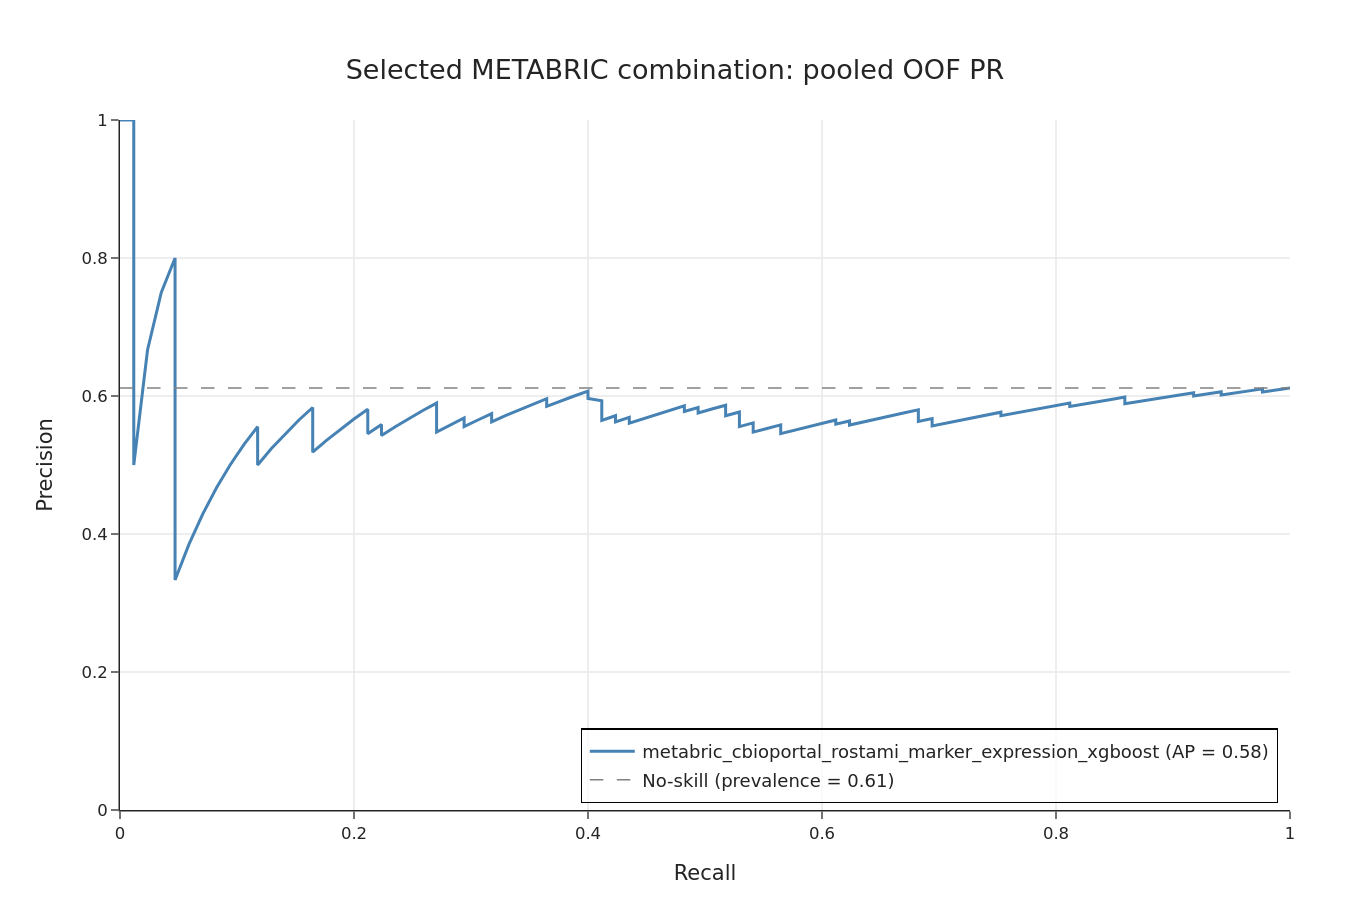

--- Plotting Confusion Matrix ---


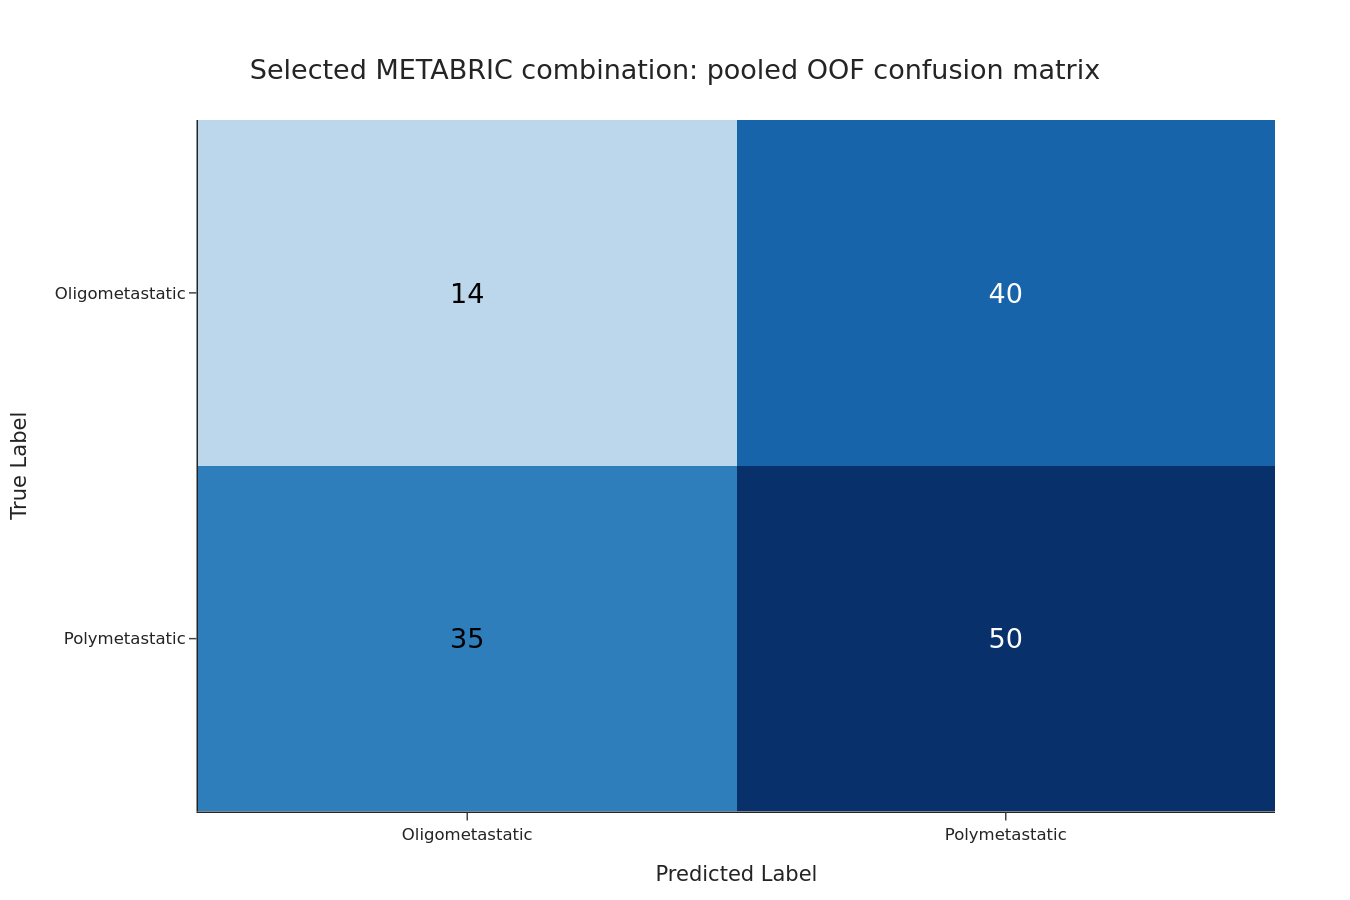

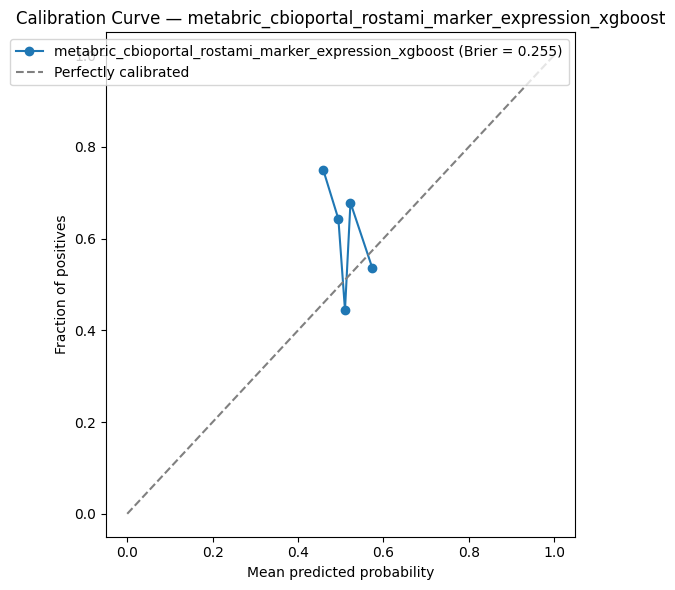

Pooled OOF Brier score: 0.255


In [19]:
if selected_combination is not None:
    selected_predictions_df = validated_oof[selected_combination]
    curve = [{"y_true": selected_predictions_df.y_true.to_numpy(), "y_prob": selected_predictions_df.y_prob_poly.to_numpy(), "label": selected_combination, "is_main_curve": True}]
    plot_roc_curves(curve, title="Selected METABRIC combination: pooled OOF ROC", interactive=False)
    plot_precision_recall_curves(curve, title="Selected METABRIC combination: pooled OOF PR", interactive=False)
    plot_confusion_matrix(selected_predictions_df.y_true, selected_predictions_df.y_pred,
        class_labels=["Oligometastatic", "Polymetastatic"], title="Selected METABRIC combination: pooled OOF confusion matrix", interactive=False)
    brier = plot_calibration_curve(selected_predictions_df.rename(columns={"representation": "model", "y_prob_poly": "y_proba"}), selected_combination, n_bins=5)
    thesis_print("Pooled OOF Brier score:", brier)


## Predictive performance

The selected model's pooled OOF ROC-AUC was 0.426035, balanced accuracy 0.423747 and macro-F1 0.421637. Precision was 0.555556, sensitivity 0.588235 and specificity 0.259259; oligometastatic cases were therefore recognised particularly poorly at the evaluated threshold. Average precision was 0.581400 and Brier score was 0.254616. These results provide no evidence of robust predictive generalisation in this cohort/task.

An AUC below 0.5 does not establish an inverse biological signal or justify reversing predictions after observing test outcomes. Poor performance also does not prove absence of relevant biology. Small sample size, cross-platform transfer and a representation learned for subtype structure rather than metastatic extent are plausible limitations, but their separate effects were not established.


## Descriptive representation structure

UMAP and silhouette are computed separately for marker expression and four-dimensional reconstruction error. They are post-hoc descriptions, not selection or tuning criteria.


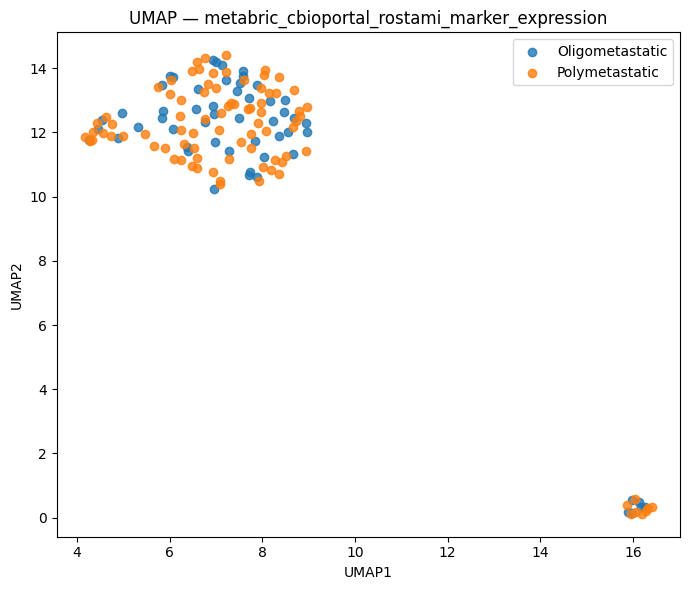

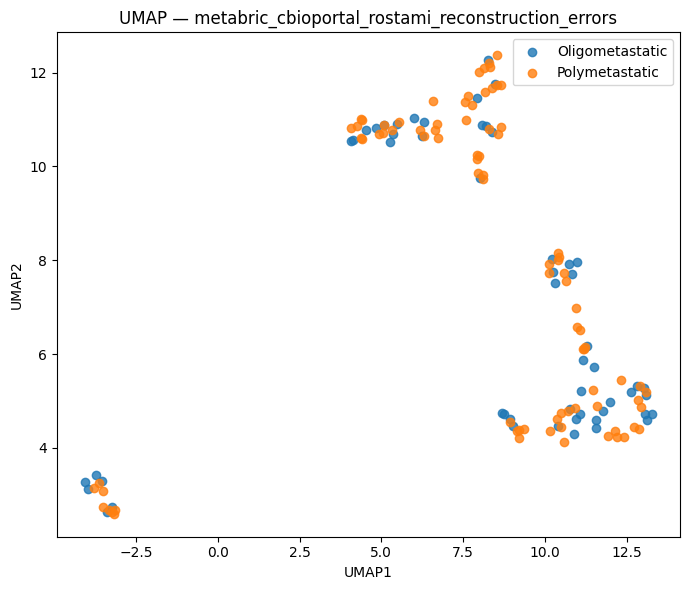

In [2]:
with warnings.catch_warnings():
    warnings.filterwarnings(
        "ignore",
        message=r"^n_jobs value 1 overridden to 1 by setting random_state\. Use no seed for parallelism\.$",
        category=UserWarning,
        module=r"^umap\.umap_$",
    )
    if RUN_EXPLORATORY:
        if len(fixed_representations)!=2: raise ValueError('Both canonical representations required')
        rows = []
        for name,(features,labels) in fixed_representations.items():
            rows.append(compute_representation_silhouette(features,labels,name,scale=True))
            plot_umap_representation(features,labels,name,random_state=42,scale=True)
        pd.DataFrame(rows).to_csv(output_dir/'rostami_silhouette_exploratory.csv',index=False)


> **Supplementary FLAML analysis.** These FLAML (AutoML) results are retained as a supplementary analysis and are not reported in the submitted thesis.

## Aligned FLAML comparator

Each representation uses the same outer splits, five stratified inner folds, macro-F1, seed 42 and 120 seconds per outer fold. Preprocessing and sampling are inside the fitted pipelines. A separate 120-second full-cohort search is interpretation-only. FLAML never replaces manual selection.

FLAML receives an explicit `StratifiedKFold(n_splits=5, shuffle=True, random_state=42)` for inner validation, as does the manual search. The same ordered outer-training inputs therefore define the same inner-fold membership in the current implementation; FLAML may permute training-row order within a fold. Saved patient-level predictions confirm identical outer-test assignments. 


In [22]:
flaml_results = {}
if RUN_FLAML and len(fixed_representations) != 2:
    raise ValueError("Both canonical fixed representations are required for aligned FLAML.")
for representation, (features, labels) in fixed_representations.items():
    name = representation + "_flaml"
    paths = [output_dir / f"{name}_{kind}_aligned.csv" for kind in ["nested_test", "nested_train", "oof_predictions"]]
    score_path = score_paths[representation]
    score_fingerprint = metabric_source_fingerprint([score_path])
    flaml_manifest_path = output_dir / f"{name}_provenance_aligned.json"
    if RUN_FLAML:
        test, train, oof = run_nested_flaml_metabric_latent(features, labels, name, metadata_df, outer_splits, FLAML_TIME_BUDGET_SECONDS, RANDOM_STATE, configs=configs_by_representation[representation])
        for frame, dest in zip([test, train, oof], paths): frame.to_csv(dest, index=False)
        flaml_manifest_path.write_text(json.dumps({"score_source": score_fingerprint}, indent=2))
    elif all(p.exists() for p in paths):
        if json.loads(flaml_manifest_path.read_text()).get("score_source") != score_fingerprint:
            raise ValueError("Cached FLAML results belong to another encoder score file.")
        test, train, oof = [pd.read_csv(p) for p in paths]
    elif any(p.exists() for p in paths):
        raise ValueError("Incomplete aligned FLAML result bundle.")
    else:
        continue
    for frame in [test, train]:
        if len(frame) != 5 or set(frame.outer_fold) != set(range(1, 6)):
            raise ValueError("Five unique FLAML outer-fold results required.")
    protocol = pd.concat([test, train, oof], ignore_index=True)
    if not protocol.inner_n_splits.eq(5).all() or not protocol.selection_metric.eq("macro_f1").all():
        raise ValueError("Saved FLAML protocol is not aligned.")
    if protocol.time_budget_seconds.nunique() != 1 or (FLAML_TIME_BUDGET_SECONDS is not None and not protocol.time_budget_seconds.eq(FLAML_TIME_BUDGET_SECONDS).all()):
        raise ValueError("FLAML budget mismatch.")
    oof = validate_tpm_oof(oof, name, metadata_df, y, outer_splits)
    pooled = {"representation": name, **tpm_pooled_oof_metrics(oof), "mean_inner_cv_score": test.best_inner_score.mean(), "mean_outer_roc_auc": test.roc_auc.mean()}
    pd.DataFrame([pooled]).to_csv(output_dir / f"{name}_pooled_oof_metrics_aligned.csv", index=False)
    flaml_results[representation] = {"test": test, "train": train, "oof": oof, "pooled": pooled}
    flaml_metric_cols = list(tpm_pooled_oof_metrics(oof)) + ["best_inner_score"]
    flaml_fold_summary = pd.concat([train, test]).groupby("dataset")[flaml_metric_cols].agg(["mean", "std"])
    flaml_fold_summary.to_csv(output_dir / f"{name}_fold_metrics_mean_sd_aligned.csv")
    thesis_display(test, train, pd.DataFrame([pooled]), flaml_fold_summary)
if selected_combination is not None and len(flaml_results) == 2:
    manual_comparison = pooled_oof_df.join(summary_df[["mean_inner_cv_score", "mean_test_roc_auc"]]).rename(columns={"mean_test_roc_auc": "mean_outer_roc_auc"})
    comparison = pd.concat([manual_comparison.reset_index(), pd.DataFrame([v["pooled"] for v in flaml_results.values()])], ignore_index=True)
    comparison.to_csv(output_dir / "rostami_manual_vs_flaml_aligned.csv", index=False)
    thesis_display(comparison)


,representation,outer_fold,best_inner_score,best_params,selection_metric,inner_n_splits,time_budget_seconds,dataset,roc_auc,balanced_accuracy,f1_macro,precision,recall,specificity,average_precision,brier_score
0,metabric_cbioportal_rostami_marker_expression_...,1,0.495,"{""best_estimator"": ""metabric_latent_xgboost"", ...",macro_f1,5,120,test,0.540,0.492,0.490,0.600,0.529,0.455,0.683,0.248
1,metabric_cbioportal_rostami_marker_expression_...,2,0.480,"{""best_estimator"": ""metabric_latent_xgboost"", ...",macro_f1,5,120,test,0.465,0.519,0.509,0.619,0.765,0.273,0.565,0.249
2,metabric_cbioportal_rostami_marker_expression_...,3,0.596,"{""best_estimator"": ""metabric_latent_xgboost"", ...",macro_f1,5,120,test,0.369,0.398,0.367,0.545,0.706,0.091,0.549,0.271
3,metabric_cbioportal_rostami_marker_expression_...,4,0.520,"{""best_estimator"": ""metabric_latent_xgboost"", ...",macro_f1,5,120,test,0.326,0.313,0.314,0.429,0.353,0.273,0.539,0.255
4,metabric_cbioportal_rostami_marker_expression_...,5,0.558,"{""best_estimator"": ""metabric_latent_xgboost"", ...",macro_f1,5,120,test,0.388,0.415,0.416,0.562,0.529,0.300,0.593,0.289


,representation,outer_fold,best_inner_score,best_params,selection_metric,inner_n_splits,time_budget_seconds,dataset,roc_auc,balanced_accuracy,f1_macro,precision,recall,specificity,average_precision,brier_score
0,metabric_cbioportal_rostami_marker_expression_...,1,0.495,"{""best_estimator"": ""metabric_latent_xgboost"", ...",macro_f1,5,120,train,0.991,0.916,0.923,0.917,0.971,0.860,0.995,0.161
1,metabric_cbioportal_rostami_marker_expression_...,2,0.480,"{""best_estimator"": ""metabric_latent_xgboost"", ...",macro_f1,5,120,train,0.973,0.879,0.877,0.910,0.897,0.860,0.982,0.237
2,metabric_cbioportal_rostami_marker_expression_...,3,0.596,"{""best_estimator"": ""metabric_latent_xgboost"", ...",macro_f1,5,120,train,0.958,0.863,0.866,0.886,0.912,0.814,0.975,0.152
3,metabric_cbioportal_rostami_marker_expression_...,4,0.520,"{""best_estimator"": ""metabric_latent_xgboost"", ...",macro_f1,5,120,train,0.824,0.715,0.715,0.779,0.779,0.651,0.870,0.235
4,metabric_cbioportal_rostami_marker_expression_...,5,0.558,"{""best_estimator"": ""metabric_latent_xgboost"", ...",macro_f1,5,120,train,0.999,0.955,0.962,0.944,1.000,0.909,1.000,0.107


,representation,roc_auc,balanced_accuracy,f1_macro,precision,recall,specificity,average_precision,brier_score,mean_inner_cv_score,mean_outer_roc_auc
0,metabric_cbioportal_rostami_marker_expression_...,0.429,0.427,0.426,0.557,0.576,0.278,0.571,0.262,0.530,0.418


roc_auc           balanced_accuracy            f1_macro            \
             mean       std              mean       std      mean       std   
dataset                                                                       
test     0.418  0.085          0.427  0.082  0.419  0.082   
train    0.949  0.072          0.865  0.091  0.869  0.094   

        precision              recall           specificity            \
             mean       std      mean       std        mean       std   
dataset                                                                 
test     0.551  0.074  0.576  0.163    0.278  0.129   
train    0.887  0.064  0.912  0.085    0.819  0.100   

        average_precision           brier_score           best_inner_score  \
                     mean       std        mean       std             mean   
dataset                                                                      
test             0.586  0.058    0.262  0.018         0.530   
train            0.964  0.053    0.179  0.056         0.530   

                   
              std  
dataset            
test     0.047  
train    0.047

,representation,outer_fold,best_inner_score,best_params,selection_metric,inner_n_splits,time_budget_seconds,dataset,roc_auc,balanced_accuracy,f1_macro,precision,recall,specificity,average_precision,brier_score
0,metabric_cbioportal_rostami_reconstruction_err...,1,0.524,"{""best_estimator"": ""metabric_latent_xgboost"", ...",macro_f1,5,120,test,0.361,0.356,0.352,0.500,0.529,0.182,0.565,0.255
1,metabric_cbioportal_rostami_reconstruction_err...,2,0.466,"{""best_estimator"": ""metabric_latent_xgboost"", ...",macro_f1,5,120,test,0.553,0.551,0.551,0.647,0.647,0.455,0.638,0.248
2,metabric_cbioportal_rostami_reconstruction_err...,3,0.518,"{""best_estimator"": ""metabric_latent_xgboost"", ...",macro_f1,5,120,test,0.422,0.430,0.429,0.556,0.588,0.273,0.591,0.252
3,metabric_cbioportal_rostami_reconstruction_err...,4,0.571,"{""best_estimator"": ""metabric_latent_xgboost"", ...",macro_f1,5,120,test,0.447,0.556,0.490,0.714,0.294,0.818,0.646,0.254
4,metabric_cbioportal_rostami_reconstruction_err...,5,0.579,"{""best_estimator"": ""metabric_latent_xgboost"", ...",macro_f1,5,120,test,0.329,0.315,0.310,0.500,0.529,0.100,0.613,0.278


,representation,outer_fold,best_inner_score,best_params,selection_metric,inner_n_splits,time_budget_seconds,dataset,roc_auc,balanced_accuracy,f1_macro,precision,recall,specificity,average_precision,brier_score
0,metabric_cbioportal_rostami_reconstruction_err...,1,0.524,"{""best_estimator"": ""metabric_latent_xgboost"", ...",macro_f1,5,120,train,0.792,0.741,0.726,0.839,0.691,0.791,0.858,0.238
1,metabric_cbioportal_rostami_reconstruction_err...,2,0.466,"{""best_estimator"": ""metabric_latent_xgboost"", ...",macro_f1,5,120,train,0.589,0.549,0.531,0.667,0.471,0.628,0.668,0.249
2,metabric_cbioportal_rostami_reconstruction_err...,3,0.518,"{""best_estimator"": ""metabric_latent_xgboost"", ...",macro_f1,5,120,train,0.657,0.586,0.573,0.698,0.544,0.628,0.740,0.248
3,metabric_cbioportal_rostami_reconstruction_err...,4,0.571,"{""best_estimator"": ""metabric_latent_xgboost"", ...",macro_f1,5,120,train,0.713,0.606,0.556,0.771,0.397,0.814,0.797,0.235
4,metabric_cbioportal_rostami_reconstruction_err...,5,0.579,"{""best_estimator"": ""metabric_latent_xgboost"", ...",macro_f1,5,120,train,0.814,0.711,0.714,0.764,0.809,0.614,0.862,0.199


,representation,roc_auc,balanced_accuracy,f1_macro,precision,recall,specificity,average_precision,brier_score,mean_inner_cv_score,mean_outer_roc_auc
0,metabric_cbioportal_rostami_reconstruction_err...,0.424,0.444,0.444,0.564,0.518,0.370,0.587,0.257,0.531,0.423


roc_auc           balanced_accuracy            f1_macro            \
             mean       std              mean       std      mean       std   
dataset                                                                       
test     0.423  0.087          0.442  0.110  0.426  0.098   
train    0.713  0.094          0.639  0.083  0.620  0.093   

        precision              recall           specificity            \
             mean       std      mean       std        mean       std   
dataset                                                                 
test     0.583  0.095  0.518  0.134    0.365  0.285   
train    0.748  0.068  0.582  0.167    0.695  0.099   

        average_precision           brier_score           best_inner_score  \
                     mean       std        mean       std             mean   
dataset                                                                      
test             0.611  0.033    0.258  0.012         0.531   
train            0.785  0.082    0.233  0.020         0.531   

                   
              std  
dataset            
test     0.046  
train    0.046

,representation,roc_auc,balanced_accuracy,f1_macro,precision,recall,specificity,average_precision,brier_score,mean_inner_cv_score,mean_outer_roc_auc
0,metabric_cbioportal_rostami_marker_expression_...,0.501,0.511,0.508,0.622,0.541,0.481,0.628,0.275,0.499,0.471
1,metabric_cbioportal_rostami_marker_expression_...,0.493,0.501,0.496,0.612,0.706,0.296,0.604,0.249,0.514,0.496
2,metabric_cbioportal_rostami_marker_expression_...,0.426,0.424,0.422,0.556,0.588,0.259,0.581,0.255,0.548,0.428
3,metabric_cbioportal_rostami_reconstruction_err...,0.476,0.474,0.464,0.585,0.447,0.500,0.623,0.251,0.484,0.476
4,metabric_cbioportal_rostami_reconstruction_err...,0.462,0.442,0.441,0.568,0.588,0.296,0.621,0.258,0.507,0.480
5,metabric_cbioportal_rostami_reconstruction_err...,0.380,0.431,0.432,0.556,0.529,0.333,0.548,0.257,0.522,0.400
6,metabric_cbioportal_rostami_marker_expression_...,0.429,0.427,0.426,0.557,0.576,0.278,0.571,0.262,0.530,0.418
7,metabric_cbioportal_rostami_reconstruction_err...,0.424,0.444,0.444,0.564,0.518,0.370,0.587,0.257,0.531,0.423


## Interpretation of the FLAML comparison

Aligned FLAML pooled OOF ROC-AUC was 0.429412 for marker expression and 0.424074 for reconstruction errors. Both remained weak: automated search did not recover robust discrimination under the specified protocol and budget. The small numerical difference from the manual marker-expression model does not establish a meaningful improvement. FLAML is a comparator and does not replace selection by manual mean inner-CV macro-F1.


In [23]:
if RUN_FULL_COHORT_FLAML:
    if selected_combination is None:
        raise ValueError("Freeze manual selection before full-cohort FLAML interpretation.")
    selected_config = rostami_registry[selected_combination]
    representation = selected_config["representation"]
    if representation not in flaml_results or not flaml_results[representation]["test"].time_budget_seconds.eq(FLAML_TIME_BUDGET_SECONDS).all():
        raise ValueError("Load/run aligned nested FLAML using the same common budget first.")
    full_automl = fit_metabric_latent_flaml(selected_config["X"], selected_config["y"], FLAML_TIME_BUDGET_SECONDS, RANDOM_STATE, configs=configs_by_representation[representation])
    flaml_ranking = extract_fitted_tpm_feature_rankings(full_automl.model.estimator, selected_config["X"].columns)
    flaml_ranking.to_csv(output_dir / f"{representation}_flaml_feature_ranking_full_cohort_tuned.csv", index=False)
    (output_dir / f"{representation}_flaml_params_full_cohort_tuned.json").write_text(json.dumps({
        "best_estimator": full_automl.best_estimator, "best_config": full_automl.best_config,
        "best_inner_score": 1-full_automl.best_loss, "n_splits": 5, "metric": "macro_f1",
        "time_budget_seconds": FLAML_TIME_BUDGET_SECONDS, "interpretation_only": True}, indent=2, default=str))
    display_interpretation(flaml_ranking.head(20))


,feature,importance,feature_score,rank
0,FAM3B,0.0298,0.030,1
1,QPRT,0.0201,0.020,2
2,CNTNAP2,0.0197,0.020,3
3,NUPR2,0.0190,0.019,4
4,NDP,0.0187,0.019,5
5,CEL,0.0183,0.018,6
6,GSTM1,0.0175,0.018,7
7,RASSF10,0.0173,0.017,8
8,IGSF1,0.0171,0.017,9
9,UGT2B11,0.0170,0.017,10


## Scientific conclusion

The Rostami-derived marker-expression and reconstruction-error representations did not demonstrate improved oligo-versus-poly prediction in this cohort. The selected marker-expression + XGBoost combination generalised poorly, with a large train–test gap consistent with substantial overfitting; reconstruction-error results were also weak. The experiment therefore does not support a clinically useful classifier for this task. The predictive limitations do not rule out biologically relevant expression structure.
